In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import re
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
CLEAN_PATH = "D:/New Folder/CLEAN_REFIT_081116"
OUTPUT_PATH = "D:/New Folder/REFIT_EDA_Results/"

os.makedirs(OUTPUT_PATH, exist_ok=True)

In [4]:
washing_machine_mapping = {
    2: 'Appliance2',
    3: 'Appliance6',
    5: 'Appliance3',
    6: 'Appliance2'
}

selected_houses = list(washing_machine_mapping.keys())

day_names = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

In [5]:
household_data = {}

for house, washing_column in washing_machine_mapping.items():

    file_path = os.path.join(
        CLEAN_PATH,
        f"CLEAN_House{house}.csv"
    )

    temp = pd.read_csv(
        file_path,
        usecols=['Time', 'Aggregate', washing_column, 'Issues']
    )

    temp['Time'] = pd.to_datetime(temp['Time'])

    temp = temp.sort_values('Time')

    temp = temp.rename(
        columns={washing_column: 'Washing_Machine'}
    )

    household_data[house] = temp

    print(
        f"House {house}: {len(temp):,} records loaded"
    )

House 2: 5,733,526 records loaded
House 3: 6,994,594 records loaded
House 5: 7,430,755 records loaded
House 6: 6,241,971 records loaded


In [6]:
quality_summary = []

for house, data in household_data.items():

    quality_summary.append({
        'House': house,
        'Total_Records': len(data),
        'Start_Date': data['Time'].min(),
        'End_Date': data['Time'].max(),
        'Missing_Aggregate': data['Aggregate'].isna().sum(),
        'Missing_Washing_Machine': data['Washing_Machine'].isna().sum(),
        'Issue_Records': (data['Issues'] == 1).sum(),
        'Issue_Percentage': (data['Issues'] == 1).mean() * 100
    })

quality_summary_df = pd.DataFrame(quality_summary)

display(quality_summary_df.round(2))

,House,Total_Records,Start_Date,End_Date,Missing_Aggregate,Missing_Washing_Machine,Issue_Records,Issue_Percentage
0,2,5733526,2013-09-17 22:08:11,2015-05-28 08:05:43,0,0,28444,0.50
1,3,6994594,2013-09-25 19:21:09,2015-06-02 10:55:42,0,0,408627,5.84
2,5,7430755,2013-09-26 09:56:09,2015-07-06 17:48:55,0,0,425766,5.73
3,6,6241971,2013-11-28 12:15:35,2015-06-28 22:14:45,0,0,34451,0.55


In [7]:
resampled_data = {}

for house, data in household_data.items():

    valid_data = data[data['Issues'] == 0].copy()

    minute_data = (
        valid_data
        .set_index('Time')[['Aggregate', 'Washing_Machine']]
        .resample('1min')
        .mean()
    )

    resampled_data[house] = minute_data

    print(
        f"House {house}: {len(minute_data):,} one-minute records"
    )

House 2: 889,078 one-minute records
House 3: 885,095 one-minute records
House 5: 933,593 one-minute records
House 6: 831,480 one-minute records


In [8]:
availability_summary = []

for house, data in resampled_data.items():

    total_minutes = len(data)

    valid_minutes = data['Washing_Machine'].notna().sum()

    availability_summary.append({
        'House': house,
        'Total_Minutes': total_minutes,
        'Valid_Minutes': valid_minutes,
        'Missing_Minutes': total_minutes - valid_minutes,
        'Availability_Percentage': (
            valid_minutes / total_minutes * 100
        )
    })

availability_df = pd.DataFrame(availability_summary)

display(availability_df.round(2))

,House,Total_Minutes,Valid_Minutes,Missing_Minutes,Availability_Percentage
0,2,889078,669445,219633,75.30
1,3,885095,748997,136098,84.62
2,5,933593,809933,123660,86.75
3,6,831480,703854,127626,84.65


In [9]:
power_summary = []

for house, data in resampled_data.items():

    wm = data['Washing_Machine'].dropna()

    nonzero = wm[wm > 0]

    power_summary.append({
        'House': house,
        'Mean_Power': wm.mean(),
        'Median_Power': wm.median(),
        'Zero_Percentage': (wm == 0).mean() * 100,
        'Nonzero_Percentage': (wm > 0).mean() * 100,
        '95th_Percentile': wm.quantile(0.95),
        '99th_Percentile': wm.quantile(0.99),
        'Maximum_Power': wm.max(),
        'Nonzero_Median': nonzero.median()
    })

power_summary_df = pd.DataFrame(power_summary)

display(power_summary_df.round(2))

,House,Mean_Power,Median_Power,Zero_Percentage,Nonzero_Percentage,95th_Percentile,99th_Percentile,Maximum_Power,Nonzero_Median
0,2,17.88,0.0,94.40,5.60,9.44,206.27,2250.56,70.10
1,3,25.03,0.0,93.26,6.74,44.10,1472.34,2111.89,92.67
2,5,22.52,0.0,52.43,47.57,64.00,464.89,2345.00,3.00
3,6,6.94,0.0,97.45,2.55,0.00,99.80,2185.00,83.18


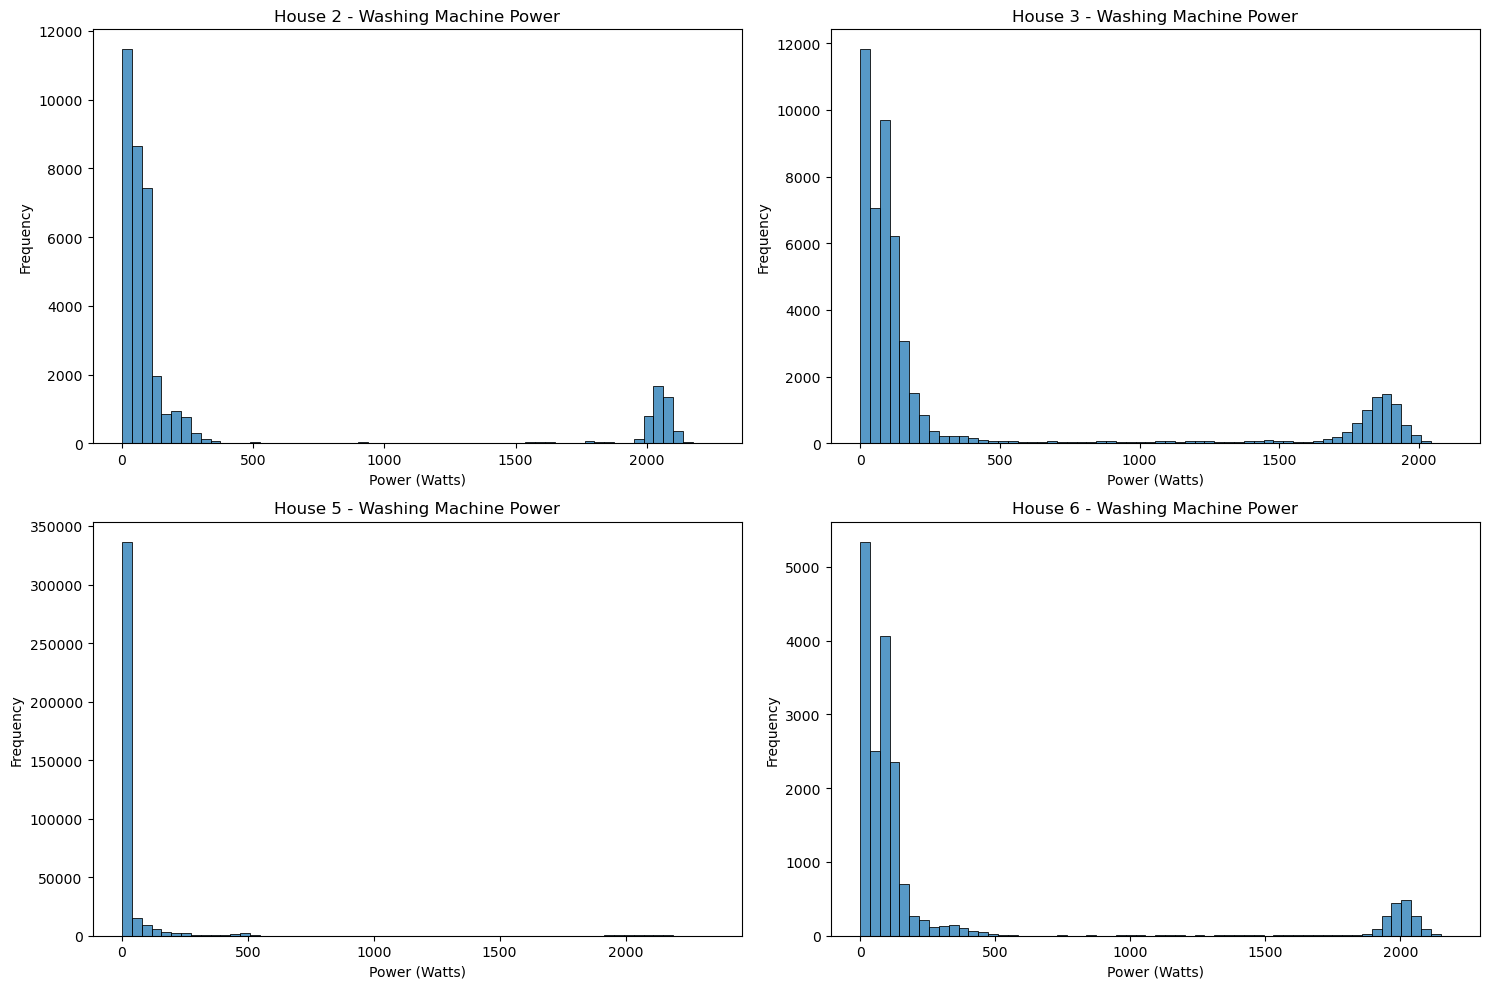

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (house, data) in zip(
    axes.flatten(), resampled_data.items()
):

    wm = data['Washing_Machine'].dropna()

    sns.histplot(
        wm[wm > 0],
        bins=60,
        ax=ax
    )

    ax.set_title(f'House {house} - Washing Machine Power')
    ax.set_xlabel('Power (Watts)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, 'power_distribution.png'),
    dpi=300
)
plt.show()

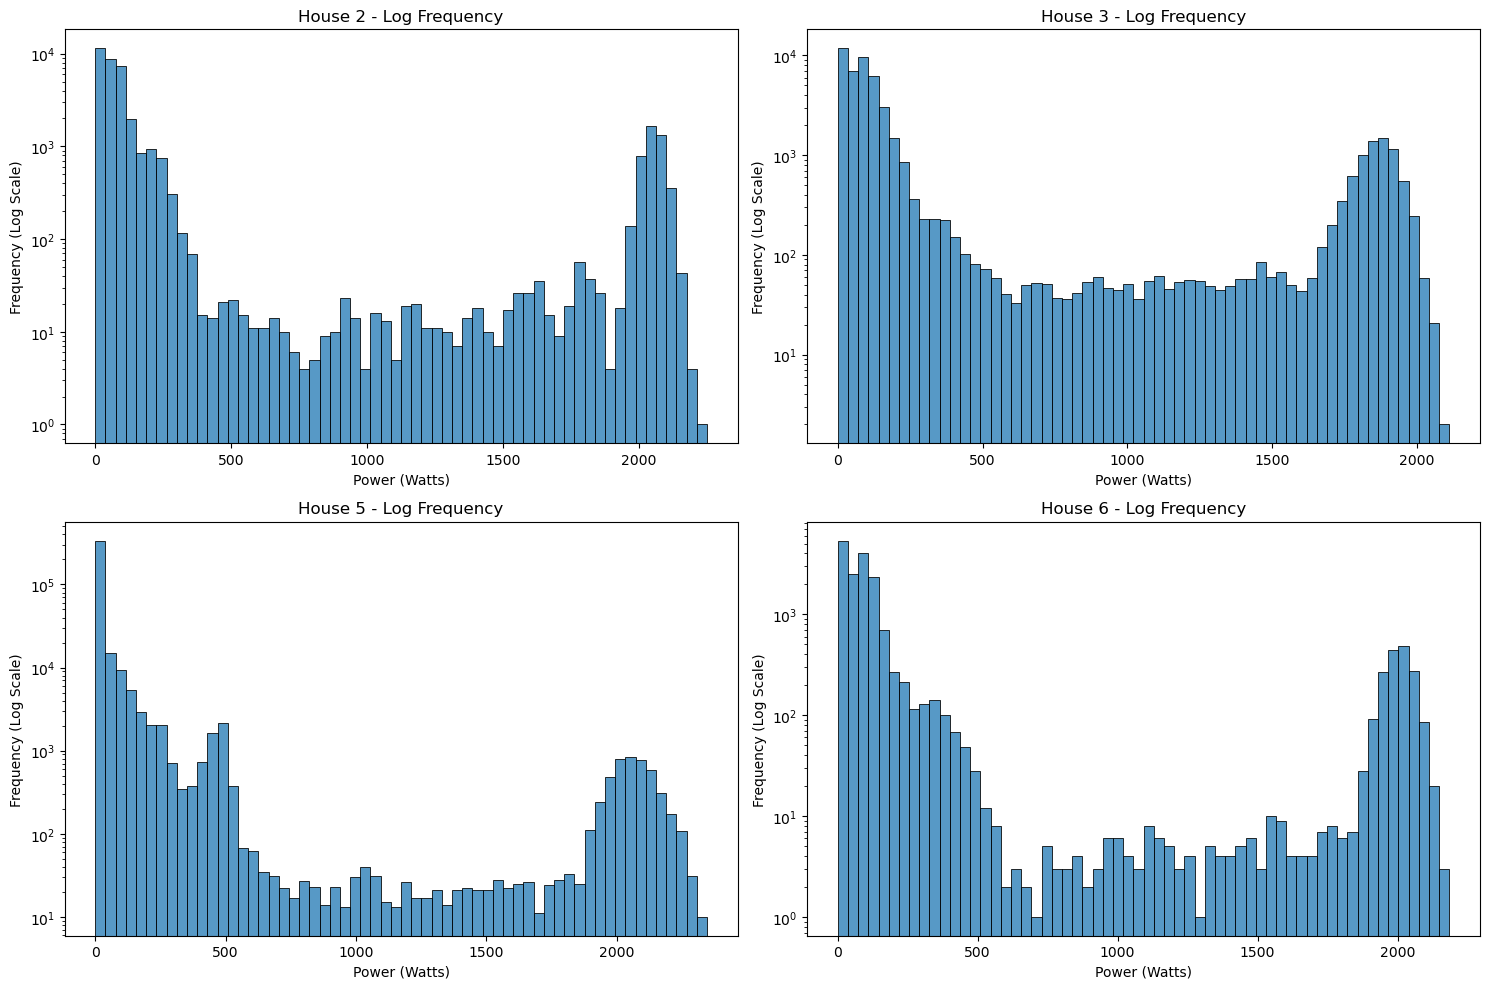

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (house, data) in zip(
    axes.flatten(), resampled_data.items()
):

    wm = data['Washing_Machine'].dropna()

    sns.histplot(
        wm[wm > 0],
        bins=60,
        ax=ax
    )

    ax.set_yscale('log')

    ax.set_title(f'House {house} - Log Frequency')
    ax.set_xlabel('Power (Watts)')
    ax.set_ylabel('Frequency (Log Scale)')

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, 'power_distribution_log.png'),
    dpi=300
)
plt.show()

In [12]:
hourly_usage = {}
daily_usage = {}

for house, data in resampled_data.items():

    wm = data['Washing_Machine'].dropna()

    hourly_usage[house] = wm.groupby(
        wm.index.hour
    ).mean().reindex(range(24))

    daily_usage[house] = wm.groupby(
        wm.index.dayofweek
    ).mean().reindex(range(7))

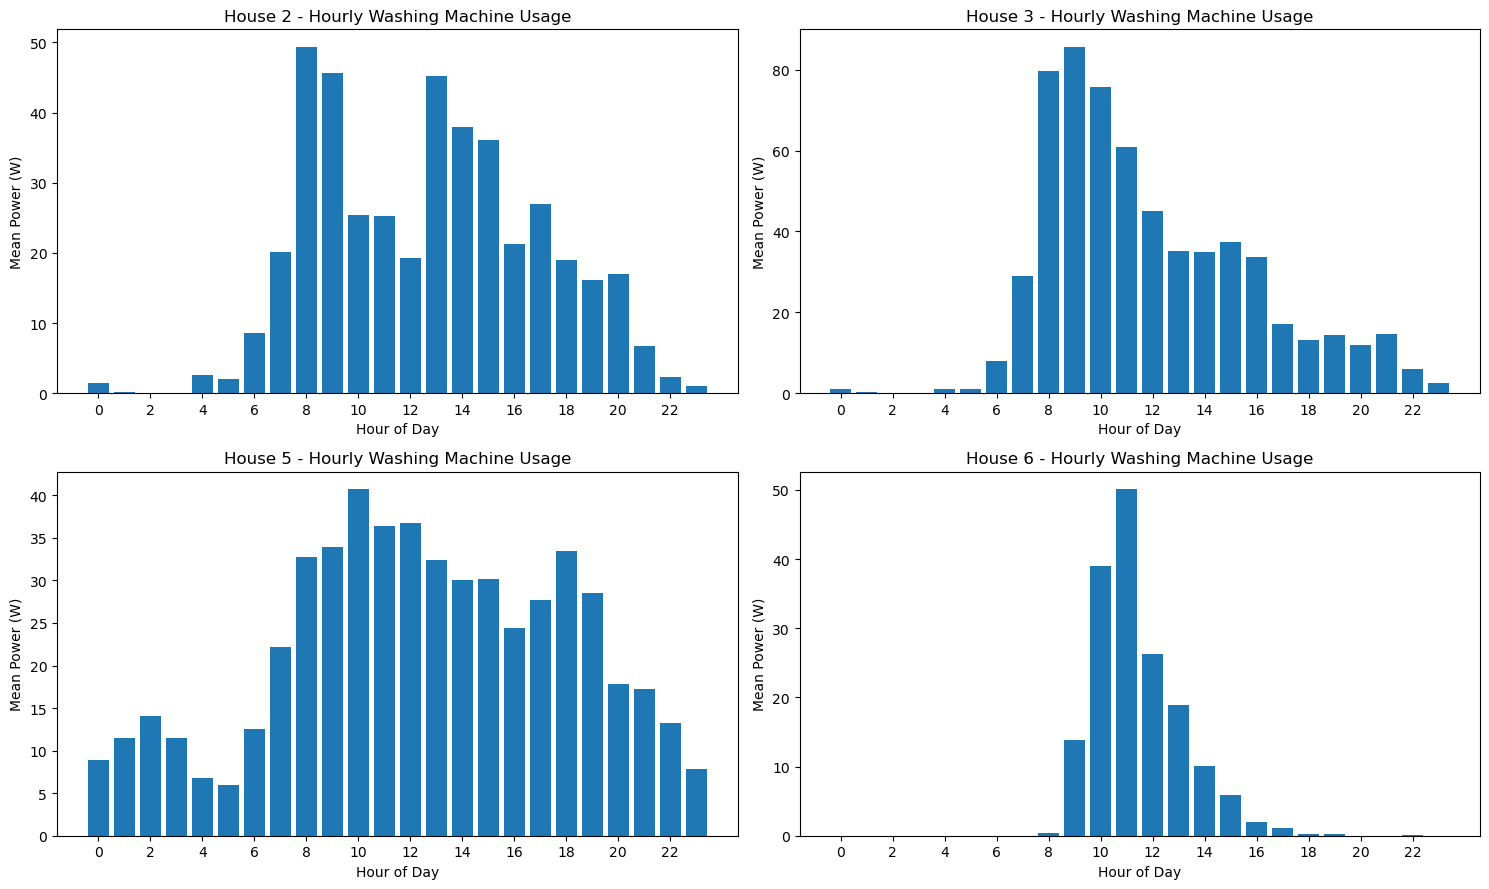

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, (house, usage) in zip(
    axes.flatten(), hourly_usage.items()
):

    ax.bar(usage.index, usage.values)

    ax.set_title(
        f'House {house} - Hourly Washing Machine Usage'
    )

    ax.set_xlabel('Hour of Day')
    ax.set_ylabel('Mean Power (W)')
    ax.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, 'hourly_usage.png'),
    dpi=300
)
plt.show()

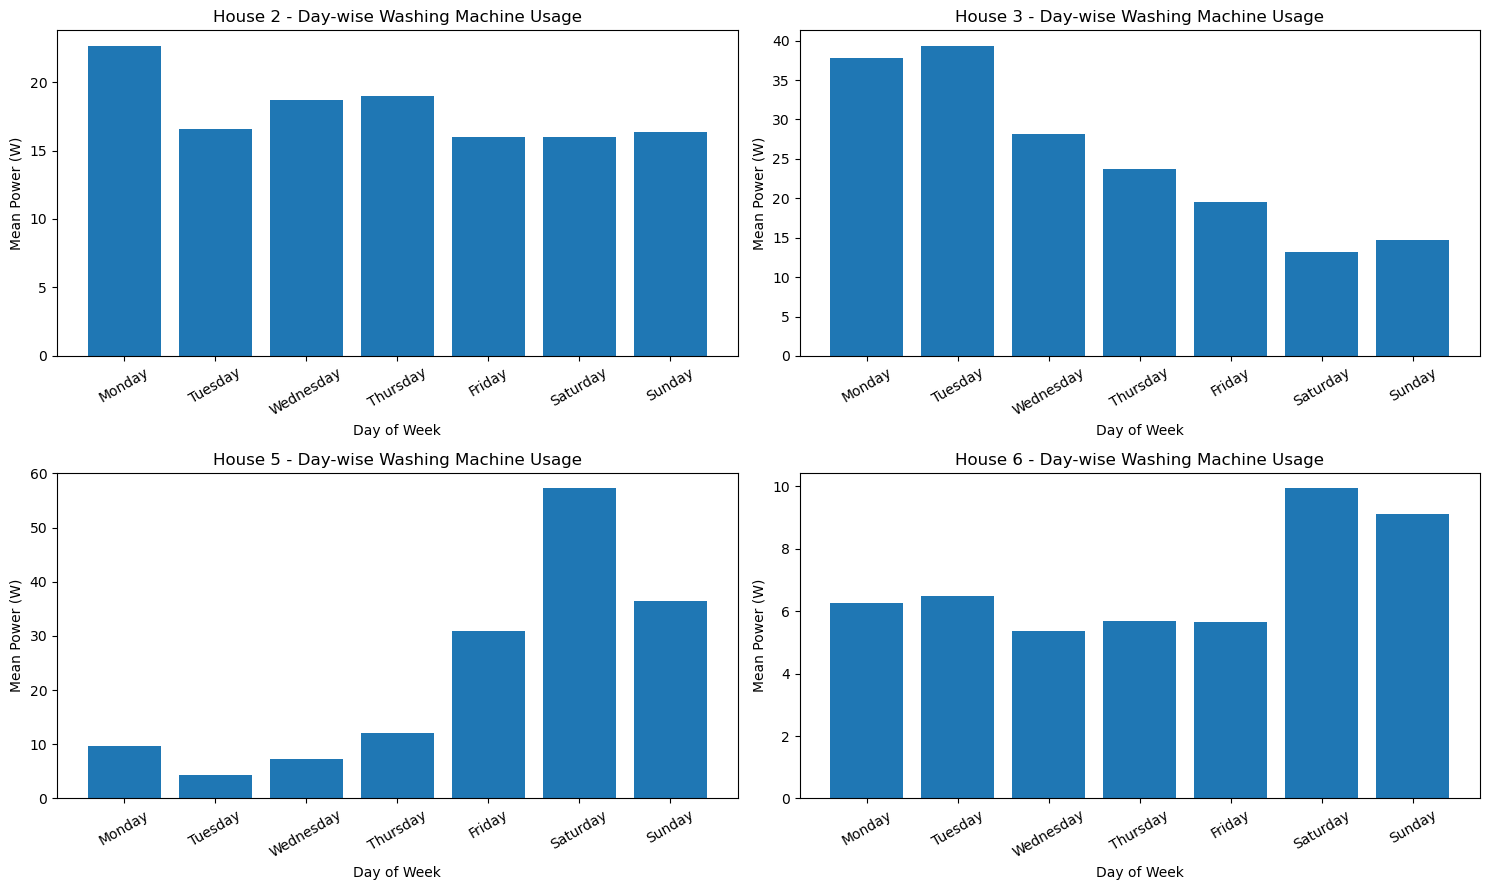

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, (house, usage) in zip(
    axes.flatten(), daily_usage.items()
):

    ax.bar(day_names, usage.values)

    ax.set_title(
        f'House {house} - Day-wise Washing Machine Usage'
    )

    ax.set_xlabel('Day of Week')
    ax.set_ylabel('Mean Power (W)')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, 'weekday_usage.png'),
    dpi=300
)
plt.show()

In [15]:
coverage_results = []

for house, data in resampled_data.items():

    wm = data['Washing_Machine']

    for hour in range(24):

        mask = data.index.hour == hour

        expected = mask.sum()
        valid = wm[mask].notna().sum()

        coverage_results.append({
            'House': house,
            'Period': f'Hour {hour}',
            'Coverage_Percent': (
                valid / expected * 100 if expected else np.nan
            )
        })

    for day in range(7):

        mask = data.index.dayofweek == day

        expected = mask.sum()
        valid = wm[mask].notna().sum()

        coverage_results.append({
            'House': house,
            'Period': day_names[day],
            'Coverage_Percent': (
                valid / expected * 100 if expected else np.nan
            )
        })

coverage_results_df = pd.DataFrame(coverage_results)

weekday_coverage = coverage_results_df[
    coverage_results_df['Period'].isin(day_names)
]

hourly_coverage = coverage_results_df[
    coverage_results_df['Period'].str.startswith('Hour')
]

print("Weekday Coverage (%)")

display(
    weekday_coverage.pivot(
        index='Period',
        columns='House',
        values='Coverage_Percent'
    ).round(2)
)

print("Hourly Coverage (%)")

display(
    hourly_coverage.pivot(
        index='Period',
        columns='House',
        values='Coverage_Percent'
    ).round(2)
)

Weekday Coverage (%)


House,2,3,5,6
Period,,,,
Friday,76.83,86.34,86.88,86.44
Monday,72.45,80.62,84.79,80.40
Saturday,75.38,85.85,86.21,86.36
Sunday,73.76,83.35,84.53,83.79
Thursday,78.35,87.87,89.30,86.95
Tuesday,73.21,82.20,86.64,83.70
Wednesday,77.06,86.14,88.95,84.86


Hourly Coverage (%)


House,2,3,5,6
Period,,,,
Hour 0,75.36,85.53,84.90,84.52
Hour 1,75.46,85.11,82.42,84.43
Hour 10,74.90,82.40,86.61,82.92
Hour 11,75.35,83.21,87.59,83.97
Hour 12,75.44,82.42,87.73,84.44
Hour 13,75.25,82.48,88.20,84.45
Hour 14,74.96,83.49,87.74,84.35
Hour 15,75.16,85.26,88.12,84.34
Hour 16,75.56,85.64,88.55,84.98


In [16]:
ACTIVATION_THRESHOLD = 200

cycle_candidates = {}

for house, data in resampled_data.items():

    wm = data['Washing_Machine']

    active = wm.gt(ACTIVATION_THRESHOLD).fillna(False)

    group_id = active.ne(active.shift()).cumsum()

    runs = pd.DataFrame({
        'Power': wm,
        'Active': active,
        'Group': group_id
    }).groupby('Group').agg(
        Start=('Power', lambda x: x.index.min()),
        End=('Power', lambda x: x.index.max()),
        Duration_Minutes=('Active', 'size'),
        Is_Active=('Active', 'first'),
        Peak_Power=('Power', 'max'),
        Mean_Power=('Power', 'mean')
    )

    active_runs = runs[runs['Is_Active']].copy()

    cycle_candidates[house] = active_runs

    print(
        f"House {house}: {len(active_runs)} active periods detected"
    )

House 2: 1474 active periods detected
House 3: 1761 active periods detected
House 5: 2875 active periods detected
House 6: 528 active periods detected


In [17]:
gap_analysis = {}

for house, events in cycle_candidates.items():

    events = events.sort_values('Start').copy()

    events['Previous_End'] = events['End'].shift(1)

    events['Gap_Minutes'] = (
        events['Start'] - events['Previous_End']
    ).dt.total_seconds() / 60

    gap_analysis[house] = events

gap_summary = []

for house, events in gap_analysis.items():

    gaps = events['Gap_Minutes'].dropna()

    gap_summary.append({
        'House': house,
        'Median_Gap_Min': gaps.median(),
        'Mean_Gap_Min': gaps.mean(),
        '25th_Percentile': gaps.quantile(0.25),
        '75th_Percentile': gaps.quantile(0.75),
        '90th_Percentile': gaps.quantile(0.90),
        '95th_Percentile': gaps.quantile(0.95)
    })

gap_summary_df = pd.DataFrame(gap_summary)

display(gap_summary_df.round(2))

,House,Median_Gap_Min,Mean_Gap_Min,25th_Percentile,75th_Percentile,90th_Percentile,95th_Percentile
0,2,18.0,597.57,13.0,44.0,1958.0,2877.20
1,3,36.0,496.87,8.0,156.5,1351.0,2719.25
2,5,14.0,319.53,7.0,54.0,541.4,1305.70
3,6,14.0,1564.20,9.0,90.0,5708.6,9913.40


In [18]:
MERGE_GAP_MINUTES = 15
MIN_ACTIVE_MINUTES = 3
MAX_SESSION_DURATION = 120

final_sessions_15 = {}

for house, events in gap_analysis.items():

    events = events.sort_values('Start').copy()

    sessions = []

    session_start = None
    session_end = None
    session_events = []

    for _, event in events.iterrows():

        if session_start is None:

            session_start = event['Start']
            session_end = event['End']
            session_events = [event]

        else:

            gap = (
                event['Start'] - session_end
            ).total_seconds() / 60

            if gap <= MERGE_GAP_MINUTES:

                session_end = event['End']
                session_events.append(event)

            else:

                sessions.append({
                    'Start': session_start,
                    'End': session_end,
                    'Duration_Minutes': (
                        session_end - session_start
                    ).total_seconds() / 60 + 1,
                    'Peak_Power': max(
                        e['Peak_Power'] for e in session_events
                    ),
                    'Active_Minutes': sum(
                        e['Duration_Minutes']
                        for e in session_events
                    ),
                    'Number_of_Active_Periods': len(session_events)
                })

                session_start = event['Start']
                session_end = event['End']
                session_events = [event]

    if session_start is not None:

        sessions.append({
            'Start': session_start,
            'End': session_end,
            'Duration_Minutes': (
                session_end - session_start
            ).total_seconds() / 60 + 1,
            'Peak_Power': max(
                e['Peak_Power'] for e in session_events
            ),
            'Active_Minutes': sum(
                e['Duration_Minutes']
                for e in session_events
            ),
            'Number_of_Active_Periods': len(session_events)
        })

    sessions_df = pd.DataFrame(sessions)

    sessions_df = sessions_df[
        (sessions_df['Active_Minutes'] >= MIN_ACTIVE_MINUTES) &
        (sessions_df['Duration_Minutes'] <= MAX_SESSION_DURATION)
    ].copy()

    final_sessions_15[house] = sessions_df

In [19]:
session_summary = []

for house, sessions in final_sessions_15.items():

    session_summary.append({
        'House': house,
        'Detected_Sessions': len(sessions),
        'Median_Duration_Min': sessions['Duration_Minutes'].median(),
        'Mean_Duration_Min': sessions['Duration_Minutes'].mean(),
        'Median_Active_Min': sessions['Active_Minutes'].median(),
        'Median_Peak_Power': sessions['Peak_Power'].median()
    })

session_summary_df = pd.DataFrame(session_summary)

display(session_summary_df.round(2))

,House,Detected_Sessions,Median_Duration_Min,Mean_Duration_Min,Median_Active_Min,Median_Peak_Power
0,2,611,17.0,21.18,8.0,2034.89
1,3,1027,12.0,13.45,10.0,1849.57
2,5,1009,12.0,19.93,8.0,2026.00
3,6,232,18.0,19.26,9.0,1932.48


In [20]:
session_energy_results = {}

for house, sessions in final_sessions_15.items():

    wm = resampled_data[house]['Washing_Machine']

    results = []

    for _, session in sessions.iterrows():

        start = session['Start']
        end = session['End']

        session_power = wm.loc[start:end].dropna()

        energy_kwh = session_power.sum() / 60000

        results.append({
            'Start': start,
            'End': end,
            'Duration_Minutes': session['Duration_Minutes'],
            'Active_Minutes': session['Active_Minutes'],
            'Peak_Power_W': session['Peak_Power'],
            'Energy_kWh': energy_kwh
        })

    session_energy_results[house] = pd.DataFrame(results)

In [21]:
energy_summary = []

for house, sessions in session_energy_results.items():

    energy_summary.append({
        'House': house,
        'Sessions': len(sessions),
        'Mean_Energy_kWh': sessions['Energy_kWh'].mean(),
        'Median_Energy_kWh': sessions['Energy_kWh'].median(),
        'Mean_Peak_Power_W': sessions['Peak_Power_W'].mean(),
        'Median_Duration_Min': sessions['Duration_Minutes'].median()
    })

energy_summary_df = pd.DataFrame(energy_summary)

display(energy_summary_df.round(3))

,House,Sessions,Mean_Energy_kWh,Median_Energy_kWh,Mean_Peak_Power_W,Median_Duration_Min
0,2,611,0.285,0.220,1268.906,17.0
1,3,1027,0.262,0.278,1257.069,12.0
2,5,1009,0.210,0.167,1455.808,12.0
3,6,232,0.292,0.095,1258.932,18.0


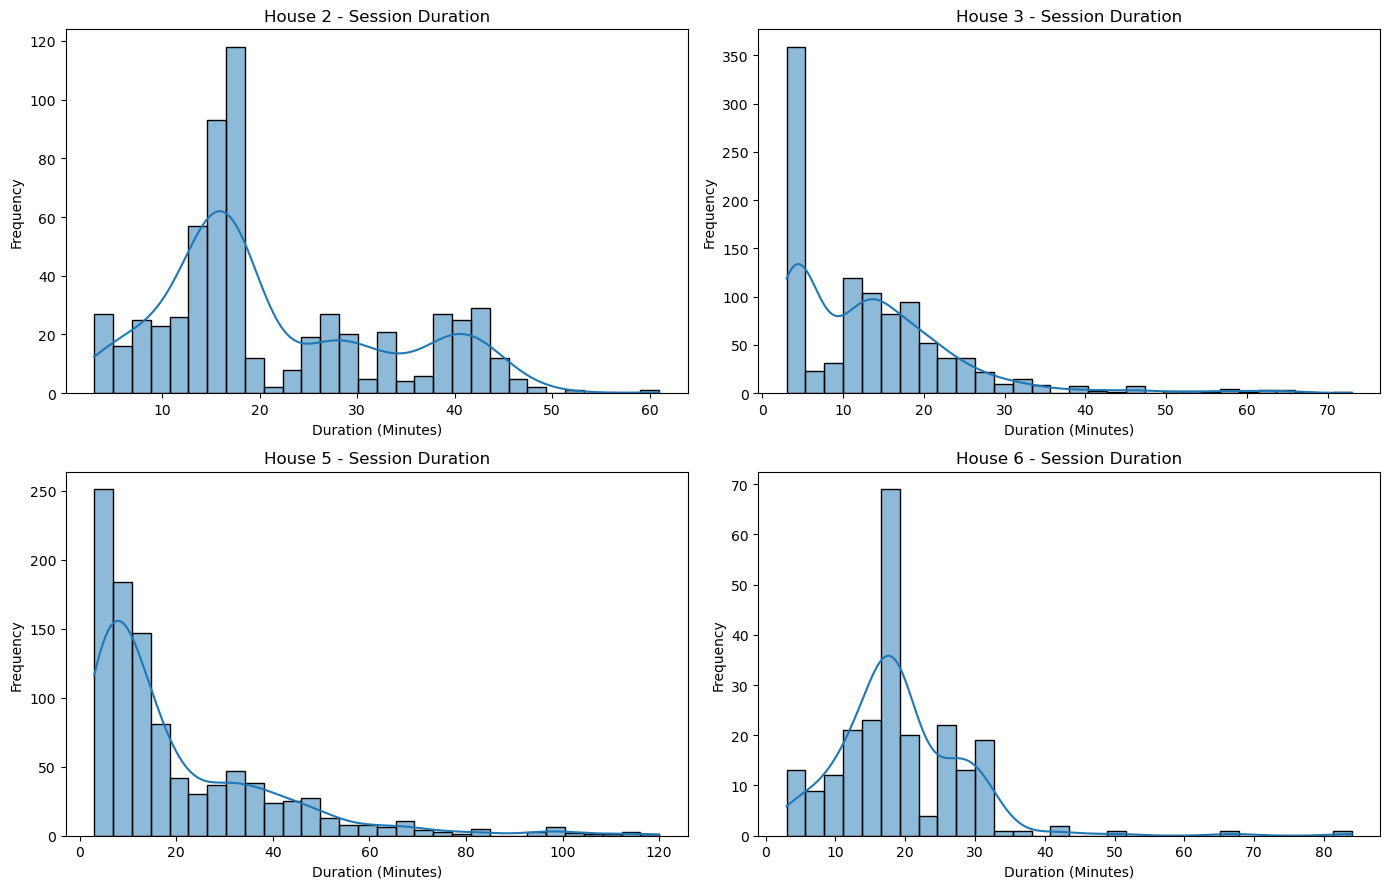

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (house, sessions) in zip(
    axes.flatten(), final_sessions_15.items()
):

    sns.histplot(
        sessions['Duration_Minutes'],
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f'House {house} - Session Duration')
    ax.set_xlabel('Duration (Minutes)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, 'session_duration.png'),
    dpi=300
)
plt.show()

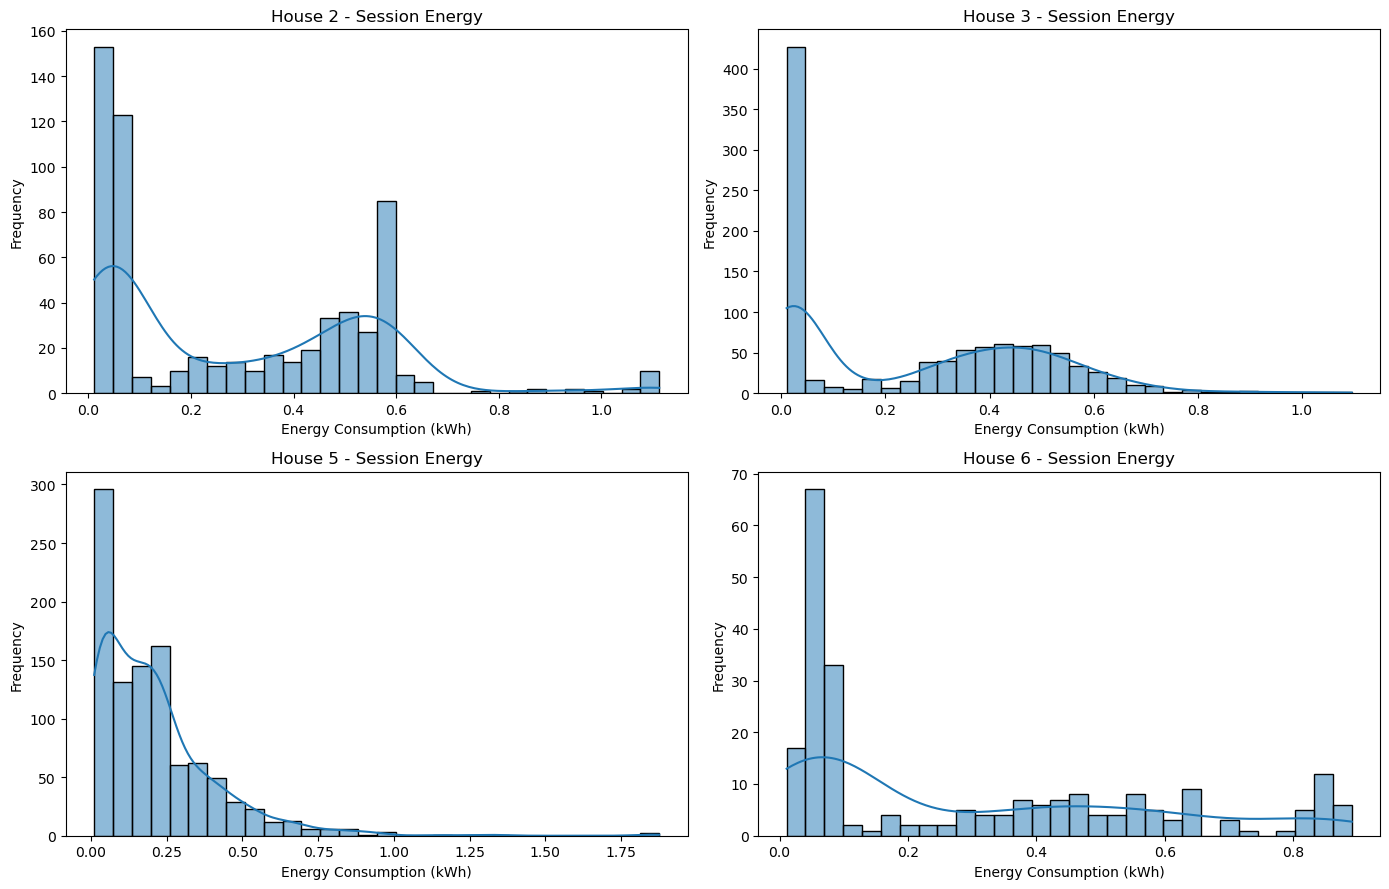

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (house, sessions) in zip(
    axes.flatten(), session_energy_results.items()
):

    sns.histplot(
        sessions['Energy_kWh'],
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f'House {house} - Session Energy')
    ax.set_xlabel('Energy Consumption (kWh)')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, 'session_energy.png'),
    dpi=300
)
plt.show()

In [24]:
comparison = energy_summary_df.merge(
    session_summary_df,
    on='House',
    suffixes=('_Energy', '_Session')
)

display(comparison.round(2))

,House,Sessions,Mean_Energy_kWh,Median_Energy_kWh,Mean_Peak_Power_W,Median_Duration_Min_Energy,Detected_Sessions,Median_Duration_Min_Session,Mean_Duration_Min,Median_Active_Min,Median_Peak_Power
0,2,611,0.29,0.22,1268.91,17.0,611,17.0,21.18,8.0,2034.89
1,3,1027,0.26,0.28,1257.07,12.0,1027,12.0,13.45,10.0,1849.57
2,5,1009,0.21,0.17,1455.81,12.0,1009,12.0,19.93,8.0,2026.00
3,6,232,0.29,0.09,1258.93,18.0,232,18.0,19.26,9.0,1932.48


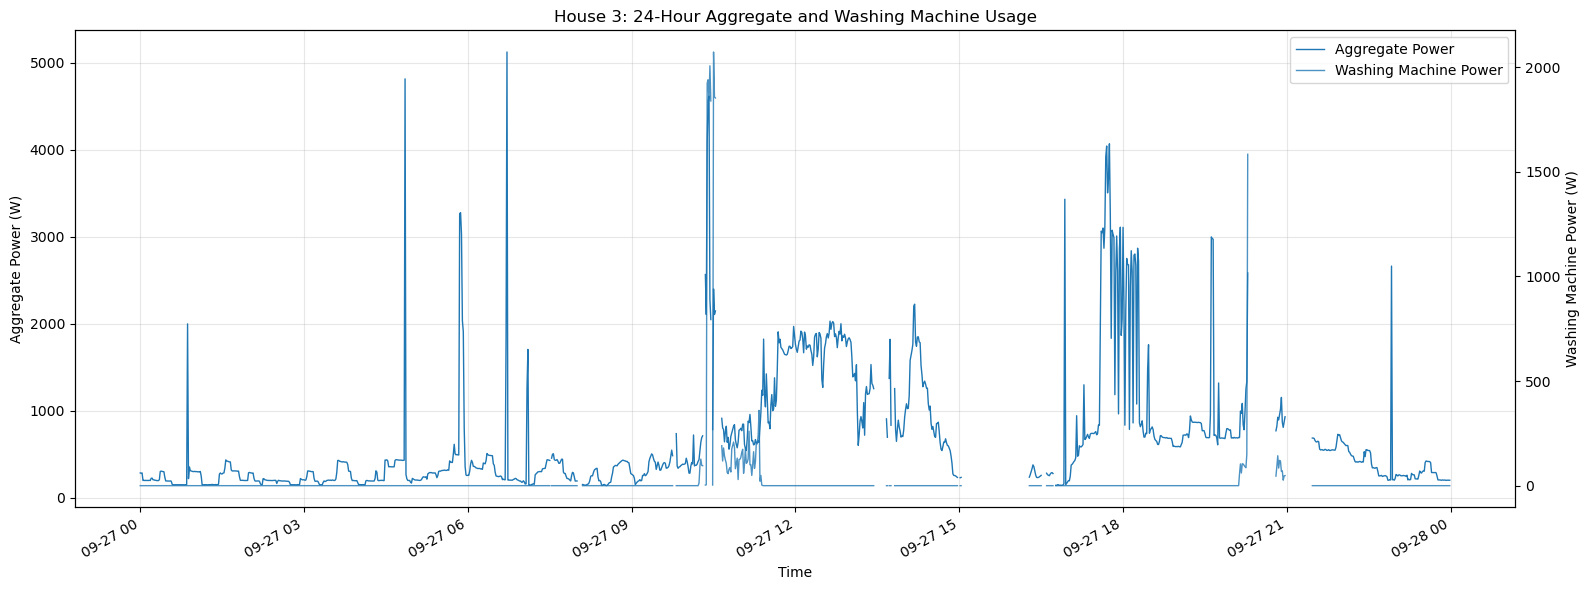

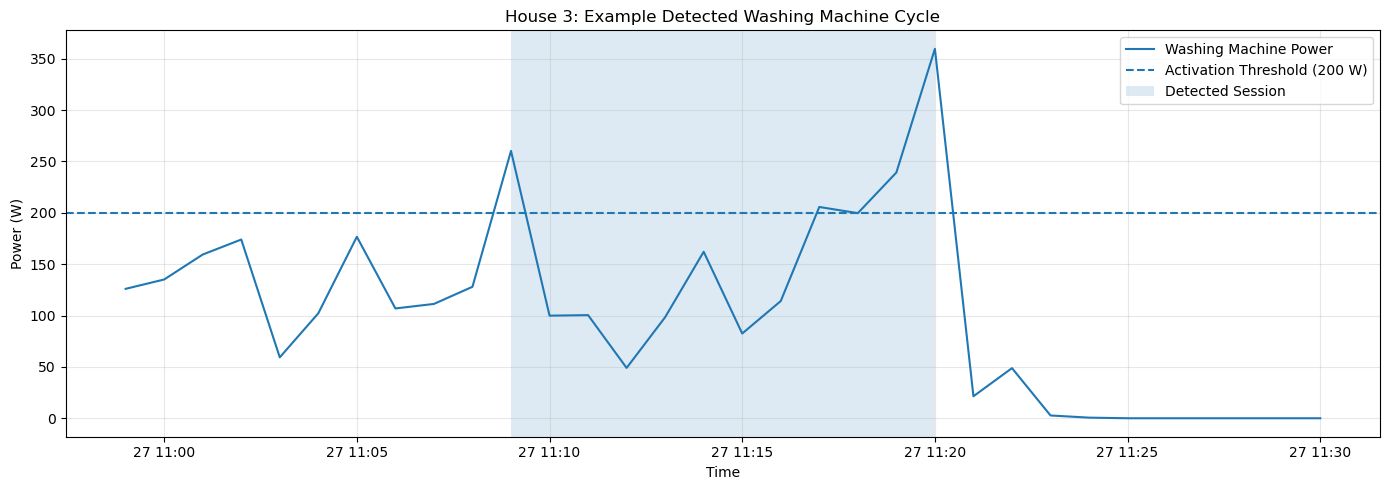

Both required EDA plots saved successfully.
Representative day: 2013-09-27 00:00:00
Selected cycle: 2013-09-27 11:09:00 to 2013-09-27 11:20:00


In [25]:
PLOT_PATH = "D:/New Folder/Flock/plots/EDA"
os.makedirs(PLOT_PATH, exist_ok=True)

house = 3
data = resampled_data[house]
sessions = final_sessions_15[house].copy()

median_duration = sessions['Duration_Minutes'].median()
selected_idx = (sessions['Duration_Minutes'] - median_duration).abs().idxmin()
selected_session = sessions.loc[selected_idx]

selected_day = selected_session['Start'].normalize()

day_data = data.loc[
    selected_day:selected_day + pd.Timedelta(hours=23, minutes=59)
]

fig, ax1 = plt.subplots(figsize=(16, 6))

ax1.plot(
    day_data.index,
    day_data['Aggregate'],
    label='Aggregate Power',
    linewidth=1
)
ax1.set_xlabel('Time')
ax1.set_ylabel('Aggregate Power (W)')
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    day_data.index,
    day_data['Washing_Machine'],
    label='Washing Machine Power',
    linewidth=1,
    alpha=0.8
)
ax2.set_ylabel('Washing Machine Power (W)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.title(f'House {house}: 24-Hour Aggregate and Washing Machine Usage')
fig.autofmt_xdate()
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_PATH, 'representative_24hour_usage.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

cycle_start = selected_session['Start']
cycle_end = selected_session['End']

cycle_data = data.loc[
    cycle_start - pd.Timedelta(minutes=10):
    cycle_end + pd.Timedelta(minutes=10)
]

plt.figure(figsize=(14, 5))

plt.plot(
    cycle_data.index,
    cycle_data['Washing_Machine'],
    label='Washing Machine Power',
    linewidth=1.5
)

plt.axhline(
    ACTIVATION_THRESHOLD,
    linestyle='--',
    label=f'Activation Threshold ({ACTIVATION_THRESHOLD} W)'
)

plt.axvspan(
    cycle_start,
    cycle_end,
    alpha=0.15,
    label='Detected Session'
)

plt.xlabel('Time')
plt.ylabel('Power (W)')
plt.title(f'House {house}: Example Detected Washing Machine Cycle')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(PLOT_PATH, 'detected_washing_machine_cycle.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print("Both required EDA plots saved successfully.")
print("Representative day:", selected_day)
print("Selected cycle:", cycle_start, "to", cycle_end)


In [26]:
quality_summary_df.to_csv(
    os.path.join(OUTPUT_PATH, 'data_quality_summary.csv'),
    index=False
)

availability_df.to_csv(
    os.path.join(OUTPUT_PATH, 'data_availability.csv'),
    index=False
)

power_summary_df.to_csv(
    os.path.join(OUTPUT_PATH, 'power_summary.csv'),
    index=False
)

session_summary_df.to_csv(
    os.path.join(OUTPUT_PATH, 'session_summary.csv'),
    index=False
)

energy_summary_df.to_csv(
    os.path.join(OUTPUT_PATH, 'energy_summary.csv'),
    index=False
)

coverage_results_df.to_csv(
    os.path.join(OUTPUT_PATH, 'coverage_summary.csv'),
    index=False
)

for house, sessions in session_energy_results.items():

    sessions.to_csv(
        os.path.join(
            OUTPUT_PATH,
            f'House{house}_candidate_sessions.csv'
        ),
        index=False
    )

print("Notebook 2 analysis outputs saved successfully.")

Notebook 2 analysis outputs saved successfully.
